# Exploratory Data Generation for E-Recruitment
This notebook demonstrates how to generate synthetic candidate data with fairness constraints using two methods: a statistical controlled generator and a FairGAN approach.

In [1]:
import sys
import os
sys.path.append(os.path.abspath('..'))

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.utils.config import load_config
from src.data.controlled_generator import ControlledGenerator
from src.data.fairgan_generator import FairGANGenerator
from src.experiments.data_generation_experiment import calculate_statistical_parity, calculate_disparate_impact

sns.set_theme(style="whitegrid")

## 1. Controlled Generation (Biased Data)
First, let's generate a dataset that exhibits bias. This acts as our baseline 'unfair' dataset.

In [2]:
data_config = load_config("../configs/data_config.yaml")
data_config['mode'] = 'biased'

biased_generator = ControlledGenerator(data_config)
df_biased = biased_generator.generate()

df_biased.head()

,id,years_experience,skills,education_level,location,preferred_work_mode,gender,race,suitability_score
0,CAND_00000,5.0,50.0,Bachelors,Urban,on-site,Male,Black,0.423564
1,CAND_00001,1.3,77.0,Bachelors,Urban,remote,Female,Other,0.323320
2,CAND_00002,0.0,76.0,Bachelors,Rural,on-site,Male,Asian,0.514510
3,CAND_00003,0.0,37.0,Bachelors,Suburban,remote,Male,Asian,0.297091
4,CAND_00004,8.8,47.0,High School,Urban,remote,Male,Hispanic,0.549352


Let's visualize the suitability score distribution by Gender and Race to observe the bias.

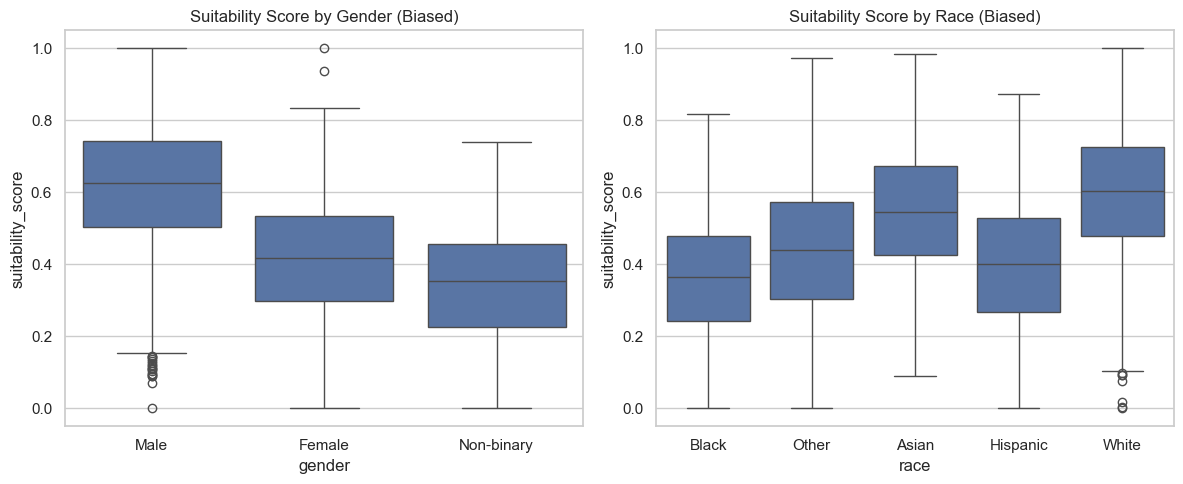

In [3]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.boxplot(data=df_biased, x='gender', y='suitability_score')
plt.title('Suitability Score by Gender (Biased)')

plt.subplot(1, 2, 2)
sns.boxplot(data=df_biased, x='race', y='suitability_score')
plt.title('Suitability Score by Race (Biased)')

plt.tight_layout()
plt.show()

## 2. FairGAN Generation
Now we will use the biased data to train a FairGAN and generate a debiased dataset.

In [4]:
gan_config = load_config("../configs/fairgan_config.yaml")
# Set small epochs for quick notebook demonstration
gan_config['epochs'] = 50 

gan = FairGANGenerator(gan_config)
gan.fit(df_biased) # Train on biased data

df_fairgan = gan.generate(data_config['n_samples'])

Preparing data for FairGAN...
Training FairGAN...
Epoch [1/50] | D Loss: 1.2033 | G Loss: 0.9588
Epoch [50/50] | D Loss: 0.3319 | G Loss: 2.8567


ValueError: Could not interpret value `gender` for `x`. An entry with this name does not appear in `data`.

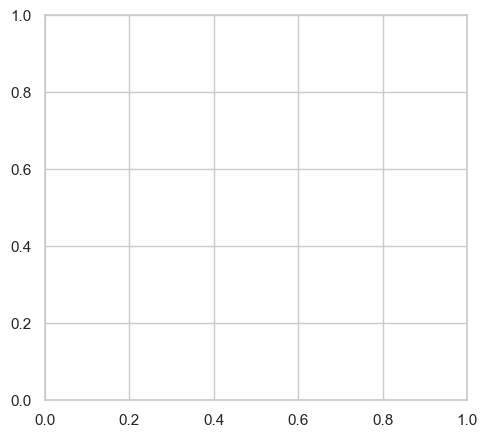

In [5]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.boxplot(data=df_fairgan, x='gender', y='suitability_score')
plt.title('Suitability Score by Gender (FairGAN)')

plt.subplot(1, 2, 2)
sns.boxplot(data=df_fairgan, x='race', y='suitability_score')
plt.title('Suitability Score by Race (FairGAN)')

plt.tight_layout()
plt.show()

## 3. Metrics Evaluation
Finally, calculate disparate impact.

In [ ]:
threshold = 0.6
print("--- Biased Data ---")
parity = calculate_statistical_parity(df_biased, 'gender', 'suitability_score', threshold)
di = calculate_disparate_impact(parity, 'Male')
print("Disparate Impact (vs Male):", di)

print("\n--- FairGAN Data ---")
parity_gan = calculate_statistical_parity(df_fairgan, 'gender', 'suitability_score', threshold)
di_gan = calculate_disparate_impact(parity_gan, 'Male')
print("Disparate Impact (vs Male):", di_gan)